In [22]:
%pip install -q gradio pandas matplotlib


In [23]:
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
import calendar
import math
from datetime import date, datetime, timedelta
from statistics import median

print("CycleSense AI libraries loaded successfully!")

CycleSense AI libraries loaded successfully!


In [24]:
def analyze_cycle(start_dates_text, period_duration):
    # Read dates separated by new lines or commas
    raw_dates = start_dates_text.replace(",", "\n").splitlines()
    raw_dates = [x.strip() for x in raw_dates if x.strip()]

    if len(raw_dates) < 2:
        raise gr.Error(
            "Please enter at least 2 previous period start dates."
        )

    dates = []

    for value in raw_dates:
        try:
            parsed = datetime.strptime(value, "%Y-%m-%d").date()
        except ValueError:
            raise gr.Error(
                f"Invalid date: {value}. Use YYYY-MM-DD format."
            )

        if parsed > date.today():
            raise gr.Error("Past period start dates only, please.")

        dates.append(parsed)

    if len(set(dates)) != len(dates):
        raise gr.Error("Duplicate dates found. Remove duplicates.")

    dates = sorted(dates)

    try:
        period_duration = int(period_duration)
    except (ValueError, TypeError):
        raise gr.Error("Enter a whole number for period duration.")

    if not 1 <= period_duration <= 15:
        raise gr.Error("Period duration must be between 1 and 15 days.")

    # Calculate the number of days between consecutive starts
    cycle_lengths = [
        (dates[i] - dates[i - 1]).days
        for i in range(1, len(dates))
    ]

    # Use the latest 6 intervals for a responsive estimate
    recent_cycles = cycle_lengths[-6:]
    typical_cycle = round(median(recent_cycles))

    # This is a heuristic range, not a medical confidence interval
    uncertainty = max(
        3,
        math.ceil((max(recent_cycles) - min(recent_cycles)) / 2)
    )

    last_start = dates[-1]
    predicted_start = last_start + timedelta(days=typical_cycle)
    earliest_start = predicted_start - timedelta(days=uncertainty)
    latest_start = predicted_start + timedelta(days=uncertainty)
    predicted_end = predicted_start + timedelta(
        days=period_duration - 1
    )

    days_remaining = (predicted_start - date.today()).days

    if days_remaining > 0:
        countdown = f"*Estimated days remaining:* {days_remaining}"
    elif days_remaining == 0:
        countdown = "*Estimated start date is today.*"
    else:
        countdown = (
            f"*Estimated date was {-days_remaining} days ago.* "
            "The estimate may need updating with newer records."
        )

    warning = ""
    if any(c < 10 or c > 100 for c in cycle_lengths):
        warning = (
            "\n\n*Note:* One or more recorded cycle intervals are "
            "unusual. Check the dates; if this pattern persists, "
            "consider discussing it with a healthcare professional."
        )

    summary = f"""
# 🌸 Your CycleSense AI Results

### Historical calculations
- *Recorded period starts:* {len(dates)}
- *Cycle lengths (days):* {", ".join(map(str, cycle_lengths))}
- *Median of recent cycles:* {typical_cycle} days
- *Recorded period duration:* {period_duration} days

### Next-period estimate
- *Estimated start:* {predicted_start.strftime("%d %B %Y")}
- *Plausible start-date range:* {earliest_start.strftime("%d %b %Y")}
  to {latest_start.strftime("%d %b %Y")}
- *Estimated period end:* {predicted_end.strftime("%d %B %Y")}
- {countdown}

The date range is a simple estimate based on variation in your
recent recorded cycles, not a statistically validated confidence
interval. Actual periods may occur earlier or later.
{warning}
"""

    # Historical cycle table
    history = pd.DataFrame({
        "Previous period start": dates[:-1],
        "Next recorded start": dates[1:],
        "Cycle length (days)": cycle_lengths
    })

    # Calendar for the month of the estimated next period
    year = predicted_start.year
    month = predicted_start.month
    cal = calendar.Calendar(firstweekday=0)
    weeks = cal.monthdayscalendar(year, month)

In [25]:
def safe_analyze_cycle(start_dates_text, period_duration):
    try:
        return analyze_cycle(start_dates_text, period_duration)
    except gr.Error as e:
        return str(e), pd.DataFrame(), pd.DataFrame(), None
    except Exception as e:
        return (
            f"Something went wrong: {type(e)._name_}: {e}",
            pd.DataFrame(),
            pd.DataFrame(),
            None
        )

In [26]:
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
import calendar
import math
import tempfile
import os
from datetime import date, datetime, timedelta
from statistics import median


def cyclesense_analyze(starts_text, ends_text):
    empty = pd.DataFrame()

    try:
        # Read dates, one per line or separated by commas
        def read_dates(text):
            items = text.replace(",", "\n").splitlines()
            items = [x.strip() for x in items if x.strip()]
            result = []
            for item in items:
                try:
                    result.append(
                        datetime.strptime(item, "%Y-%m-%d").date()
                    )
                except ValueError:
                    raise ValueError(
                        f"Invalid date '{item}'. Use YYYY-MM-DD."
                    )
            return result

        starts = read_dates(starts_text or "")
        ends = read_dates(ends_text or "")

        if len(starts) < 2:
            raise ValueError("Enter at least 2 period start dates.")

        if len(set(starts)) != len(starts):
            raise ValueError("Duplicate start dates found.")

        if any(d > date.today() for d in starts + ends):
            raise ValueError("Use past dates only.")

        if starts != sorted(starts):
            raise ValueError(
                "Enter start dates in chronological order, oldest first."
            )

        if ends and len(ends) != len(starts):
            raise ValueError(
                "Enter one end date for each start date, in the same order. "
                "If you don't know the end dates, leave that box empty."
            )

        if ends:
            for s, e in zip(starts, ends):
                if e < s:
                    raise ValueError("A period end date cannot precede its start.")
                if e >= date.today() + timedelta(days=1):
                    raise ValueError("End dates must not be in the future.")

            for i in range(len(ends) - 1):
                if ends[i] >= starts[i + 1]:
                    raise ValueError(
                        "Check the dates: a period end must be before "
                        "the next period starts."
                    )

        cycle_lengths = [
            (starts[i] - starts[i - 1]).days
            for i in range(1, len(starts))
        ]

        durations = (
            [(e - s).days + 1 for s, e in zip(starts, ends)]
            if ends else []
        )

        recent = cycle_lengths[-6:]
        typical = round(median(recent))
        variation = max(
            3,
            math.ceil((max(recent) - min(recent)) / 2)
        )

        predicted = starts[-1] + timedelta(days=typical)
        earliest = predicted - timedelta(days=variation)
        latest = predicted + timedelta(days=variation)

        if ends:
            duration_summary = (
                f"Recorded period durations: {', '.join(map(str, durations))} days\n\n"
                f"Median recorded duration: {median(durations):g} days"
            )
            estimated_end = predicted + timedelta(
                days=round(median(durations)) - 1
            )
            duration_note = (
                f"Estimated end date (based on past durations): "
                f"{estimated_end:%d %B %Y}"
            )
        else:
            duration_summary = (
                "Period durations not provided. Add matching end dates "
                "to analyse how long each period lasted."
            )
            duration_note = (
                "Estimated end date unavailable until period duration "
                "history is entered."
            )

        days_left = (predicted - date.today()).days
        if days_left > 0:
            countdown = f"{days_left} days until the estimated start"
        elif days_left == 0:
            countdown = "Estimated start date is today"
        else:
            countdown = (
                f"Estimated date was {-days_left} days ago. "
                "Check whether you have newer records."
            )

        summary = f"""
# 🌸 CycleSense AI — Your Results

## Historical analysis
- Recorded period starts: *{len(starts)}*
- Cycle lengths: *{', '.join(map(str, cycle_lengths))} days*
- Median of the most recent {len(recent)} cycles: *{typical} days*

{duration_summary}

## Next-period estimate
- Estimated start: *{predicted:%d %B %Y}*
- Estimated start-date range: *{earliest:%d %b %Y} – {latest:%d %b %Y}*
- {countdown}
- {duration_note}

*Prediction limitations:* this date range is a simple heuristic based on
recent variation, not a statistically validated confidence interval.
Periods can arrive outside this range. This app cannot diagnose medical
conditions or guarantee future dates.
"""

        history_rows = []
        for i, length in enumerate(cycle_lengths):
            row = {
                "Previous start": str(starts[i]),
                "Next start": str(starts[i + 1]),
                "Cycle length (days)": length
            }
            if ends:
                row["Previous period duration (days)"] = durations[i]
            history_rows.append(row)

        history_df = pd.DataFrame(history_rows)

        # Calendar for the estimated next-period month
        cal = calendar.Calendar(firstweekday=0)
        weeks = cal.monthdayscalendar(predicted.year, predicted.month)
        calendar_rows = []

        for week in weeks:
            row = {}
            for i, day_num in enumerate(week):
                weekday = calendar.day_abbr[i]
                if day_num == 0:
                    row[weekday] = ""
                else:
                    d = date(predicted.year, predicted.month, day_num)
                    if earliest <= d <= latest:
                        label = f"{day_num} · Estimate range"
                    elif predicted <= d <= latest:
                        label = f"{day_num} · Estimated period"
                    else:
                        label = str(day_num)
                    row[weekday] = label
            calendar_rows.append(row)

        calendar_df = pd.DataFrame(calendar_rows)

        # Cycle-history visualization
        fig, ax = plt.subplots(figsize=(9, 4))
        labels = [str(d) for d in starts[1:]]
        ax.plot(labels, cycle_lengths, marker="o")
        ax.axhline(
            typical, linestyle="--",
            label=f"Recent median: {typical} days"
        )
        ax.set_title("Recorded Cycle Lengths")
        ax.set_xlabel("Period start date")
        ax.set_ylabel("Days between starts")
        ax.legend()
        ax.grid(True, alpha=0.25)
        ax.tick_params(axis="x", rotation=35)
        fig.tight_layout()

        # Create a downloadable CSV containing entered dates and calculations
        export_df = pd.DataFrame({
            "Period start": [str(d) for d in starts],
            "Period end": (
                [str(d) for d in ends] if ends else [""] * len(starts)
            ),
            "Period duration (days)": (
                durations if ends else [""] * len(starts)
            ),
            "Cycle length to next start (days)": cycle_lengths + [""]
        })

        temp = tempfile.NamedTemporaryFile(
            suffix=".csv", delete=False
        )
        temp.close()
        export_df.to_csv(temp.name, index=False)

        return summary, history_df, calendar_df, fig, temp.name

    except Exception as e:
        return (
            f"*Please check your input:* {e}",
            empty,
            empty,
            None,
            None
        )


with gr.Blocks(
    title="CycleSense AI",
    analytics_enabled=False
) as demo:

    gr.Markdown("""
    # 🌸 CycleSense AI
    ### Period Tracker & Cycle Analytics

    Enter dates in YYYY-MM-DD format, oldest first.
    Example: 2026-06-01
    """)

    starts_input = gr.Textbox(
        label="Previous period start dates (required)",
        placeholder="2026-06-01\n2026-06-29\n2026-07-27\n2026-08-24",
        lines=5
    )

    ends_input = gr.Textbox(
        label="Matching period end dates (optional)",
        placeholder="2026-06-05\n2026-07-03\n2026-07-31\n2026-08-28",
        lines=5
    )

    calculate = gr.Button("🌸 Calculate My Cycle", variant="primary")

    summary_out = gr.Markdown()
    history_out = gr.Dataframe(label="Cycle History")
    calendar_out = gr.Dataframe(label="Estimated Period Calendar")
    chart_out = gr.Plot(label="Cycle Length Chart")
    download_out = gr.File(label="Download Your Cycle History (CSV)")

    calculate.click(
        fn=cyclesense_dashboard,
        inputs=[starts_input, ends_input],
        outputs=[
            summary_out,
            history_out,
            calendar_out,
            chart_out,
            download_out
        ]
    )

    gr.Markdown("""
    ---
    *Privacy:* this prototype does not use a database or intentionally
    save records between sessions. Downloaded CSV files are your
    responsibility to store securely. A public demo link may be accessed
    by other people; use fictional data when demonstrating the app.

    *Health note:* historical calculations are based on entered dates.
    Future dates are estimates, not medical advice or a diagnosis.
    """)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://4b3a8618934fd8503b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://4b3a8618934fd8503b.gradio.live


In [27]:
def cyclesense_dashboard(starts_text, ends_text):
    # Reuse the working tracker and its existing five outputs
    results = cyclesense_analyze(starts_text, ends_text)

    summary, history, calendar_df, fig, csv_file = results

    # Stop if the existing tracker returned a validation message
    if history.empty or "Cycle length (days)" not in history.columns:
        return results

    lengths = pd.to_numeric(
        history["Cycle length (days)"], errors="coerce"
    ).dropna()

    if lengths.empty:
        return results

    average = lengths.mean()
    middle = lengths.median()
    shortest = int(lengths.min())
    longest = int(lengths.max())
    variability = lengths.std(ddof=1) if len(lengths) > 1 else 0

    # Simple data-quality flags, not medical diagnoses
    unusual = history[
        (history["Cycle length (days)"] < 21) |
        (history["Cycle length (days)"] > 35)
    ]

    if unusual.empty:
        quality = "No intervals outside the illustrative 21–35 day range."
    else:
        quality = (
            f"{len(unusual)} interval(s) outside the illustrative "
            "21–35 day range. Check the dates; this is not a diagnosis."
        )

    duration_text = "Not available"
    if "Period duration (days)" in history.columns:
        durations = pd.to_numeric(
            history["Period duration (days)"], errors="coerce"
        ).dropna()
        if not durations.empty:
            duration_text = f"{durations.mean():.1f} days"

    dashboard = f"""
## 📊 Cycle Analytics Dashboard

| Metric | Result |
|---|---:|
| Recorded cycle intervals | {len(lengths)} |
| Average cycle length | {average:.1f} days |
| Median cycle length | {middle:.1f} days |
| Shortest recorded cycle | {shortest} days |
| Longest recorded cycle | {longest} days |
| Cycle-length standard deviation | {variability:.1f} days |
| Average recorded period duration | {duration_text} |

*Data-quality check:* {quality}

*These metrics describe the dates entered. The 21–35 day range is
an illustrative screening range, not a diagnostic rule. Individual
cycles vary, and these statistics do not establish medical normality.*
"""

    return dashboard + "\n\n" + summary, history, calendar_df, fig, csv_file


print("CycleSense analytics dashboard is ready.")

CycleSense analytics dashboard is ready.


In [28]:
import pandas as pd
import numpy as np

def evaluate_cyclesense_model(starts_text):
    # Accept dates separated by new lines or commas
    dates = [
        item.strip()
        for item in starts_text.replace(",", "\n").splitlines()
        if item.strip()
    ]

    try:
        dates = pd.to_datetime(dates, format="%Y-%m-%d")
    except ValueError:
        return "Please enter valid dates in YYYY-MM-DD format."

    dates = sorted(dates)

    if len(dates) < 5:
        return (
            "Please enter at least 5 period start dates to begin "
            "a basic evaluation. More historical dates will give "
            "a more informative result."
        )

    if len(set(dates)) != len(dates):
        return "Duplicate dates found. Please remove duplicates."

    if any((dates[i] - dates[i-1]).days <= 0
           for i in range(1, len(dates))):
        return "Dates must be in chronological order."

    cycle_lengths = pd.Series([
        (dates[i] - dates[i-1]).days
        for i in range(1, len(dates))
    ], dtype=float)

    actual = cycle_lengths.iloc[1:].to_numpy()
    predictions = []

    # Walk-forward evaluation:
    # predict each cycle using only earlier cycle lengths
    for i in range(1, len(cycle_lengths)):
        previous_lengths = cycle_lengths.iloc[:i]
        predictions.append(previous_lengths.median())

    actual = cycle_lengths.iloc[1:].to_numpy()
    predicted = np.array(predictions)

    mae = np.mean(np.abs(actual - predicted))
    baseline = np.repeat(cycle_lengths.iloc[:-1].mean(),
                         len(actual))
    baseline_mae = np.mean(np.abs(actual - baseline))

    return f"""
## 📈 CycleSense Model Evaluation

- *Evaluated predictions:* {len(actual)}
- *Median-based model MAE:* {mae:.2f} days
- *Mean-based baseline MAE:* {baseline_mae:.2f} days

*How to interpret this:* MAE measures the average absolute
difference between predicted and actual cycle lengths. Lower is
better. This is a small historical evaluation, not proof of
medical accuracy or a validated clinical prediction model.
"""

print("CycleSense evaluation function is ready.")

CycleSense evaluation function is ready.


In [29]:
print(evaluate_cyclesense_model("""
2026-01-01
2026-01-29
2026-02-26
2026-03-26
2026-04-24
2026-05-22
"""))


## 📈 CycleSense Model Evaluation

- *Evaluated predictions:* 4
- *Median-based model MAE:* 0.25 days
- *Mean-based baseline MAE:* 0.38 days

*How to interpret this:* MAE measures the average absolute
difference between predicted and actual cycle lengths. Lower is
better. This is a small historical evaluation, not proof of
medical accuracy or a validated clinical prediction model.



In [30]:
import pandas as pd
import matplotlib.pyplot as plt

def cyclesense_prediction_chart(starts_text):
    dates = [
        item.strip()
        for item in starts_text.replace(",", "\n").splitlines()
        if item.strip()
    ]

    try:
        dates = sorted(pd.to_datetime(dates, format="%Y-%m-%d"))
    except ValueError:
        print("Please enter dates in YYYY-MM-DD format.")
        return

    if len(set(dates)) != len(dates):
        print("Duplicate dates found. Please remove them.")
        return

    cycle_lengths = [
        (dates[i] - dates[i-1]).days
        for i in range(1, len(dates))
    ]

    if len(cycle_lengths) < 2:
        print("Enter at least 3 period start dates.")
        return

    actual = []
    predicted = []

    for i in range(1, len(cycle_lengths)):
        predicted.append(
            pd.Series(cycle_lengths[:i]).median()
        )
        actual.append(cycle_lengths[i])

    results = pd.DataFrame({
        "Cycle": range(2, len(cycle_lengths) + 1),
        "Actual length (days)": actual,
        "Predicted length (days)": predicted
    })

    display(results)

    plt.figure(figsize=(9, 4))
    plt.plot(results["Cycle"], results["Actual length (days)"],
             marker="o", label="Actual")
    plt.plot(results["Cycle"], results["Predicted length (days)"],
             marker="o", linestyle="--", label="Predicted")
    plt.title("CycleSense AI: Actual vs Predicted")
    plt.xlabel("Cycle number")
    plt.ylabel("Cycle length (days)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print("Prediction chart function is ready.")

Prediction chart function is ready.


,Cycle,Actual length (days),Predicted length (days)
0,2,28,28.0
1,3,28,28.0
2,4,29,28.0
3,5,28,28.0


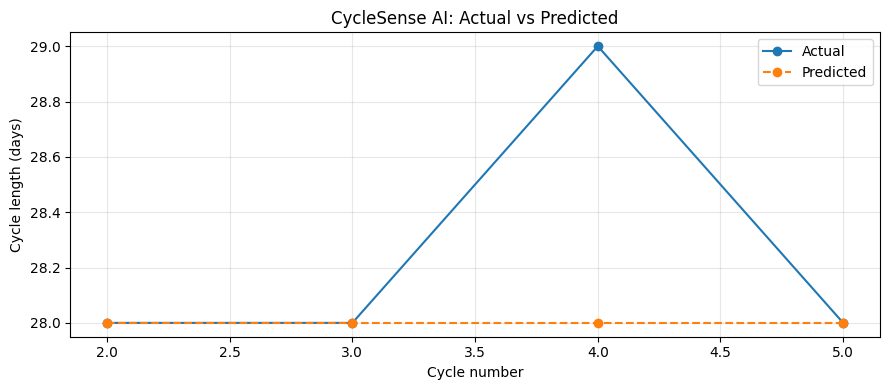

In [31]:
cyclesense_prediction_chart("""
2026-01-01
2026-01-29
2026-02-26
2026-03-26
2026-04-24
2026-05-22
""")